# Stage 8b — Group Importance and Ablation

Add the Stage 8a predictors to the exact Notebook 4 sample and let group-level evidence determine the final v2 schema. Correlated columns are interpreted jointly through Spearman correlation, grouped permutation importance, and retrained group ablation.

## Outputs

- `data/processed/supervised_sample_v2.parquet`
- `data/processed/feature_manifest_v2.json`
- `data/processed/group_importance.csv`
- `data/processed/xgb_v2_scores.csv` and `xgb_v2_scores_all_targets.csv`
- `data/processed/xgb_v2_training_audit.csv` and `xgb_v2_model_manifest.json`
- `figs/08_correlation_heatmap.png` and `figs/08_group_importance.png`
- `models/xgb_v2_h{1..7}.json`


## 8b.0 — Load and normalize the source cubes

Load CHL, SST, bathymetry, the five Stage 8a CMEMS products, and ERA5 wind. Surface-only downloads should already contain a singleton depth; the defensive `surface()` helper removes that dimension before regridding. Coordinate names and axis direction are normalized consistently.


In [17]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import xarray as xr

RAW_DIR  = Path("data/raw")
PROC_DIR = Path("data/processed"); PROC_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = Path("models");        MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR   = Path("figs");          FIG_DIR.mkdir(parents=True, exist_ok=True)

# Cubes from Notebook 1/3/8a
chl_da   = xr.open_dataset(RAW_DIR / "chl_malta_2021_2023.nc").CHL
sst_da   = xr.open_dataset(RAW_DIR / "sst_malta_2021_2023.nc").analysed_sst
bathy_ds = xr.open_dataset(RAW_DIR / "bathy_malta.nc")

phy_sal_da = xr.open_dataset(RAW_DIR / "phy_sal.nc").so
phy_cur_ds = xr.open_dataset(RAW_DIR / "phy_cur.nc")
phy_ssh_da = xr.open_dataset(RAW_DIR / "phy_ssh.nc").zos
phy_mld_da = xr.open_dataset(RAW_DIR / "phy_mld.nc").mlotst
kd490_da   = xr.open_dataset(RAW_DIR / "oc_kd490.nc").KD490

era5_path = RAW_DIR / "era5_wind_2021_2023.nc"

if not era5_path.exists():
    raise FileNotFoundError(
        "ERA5 is required for Stage 8b. "
        "Complete Notebook 8a first."
    )

era5 = xr.open_dataset(era5_path)
have_wind = True
print("ERA5 wind: present")

# Surface extraction — drops the depth dim on the 3D cubes
def surface(da):
    for cand in ("depth", "lev", "z"):
        if cand in da.dims:
            return da.isel({cand: 0}).drop_vars(cand, errors="ignore")
    return da

phy_sal_da = surface(phy_sal_da)
phy_cur_uo = surface(phy_cur_ds.uo)
phy_cur_vo = surface(phy_cur_ds.vo)
phy_ssh_da = surface(phy_ssh_da)
phy_mld_da = surface(phy_mld_da)

# Standardise lat/lon names — ERA5 uses lat/lon, CMEMS uses latitude/longitude
def std_coords(da):
    rn = {}
    if "lat" in da.coords and "latitude" not in da.coords:  rn["lat"] = "latitude"
    if "lon" in da.coords and "longitude" not in da.coords: rn["lon"] = "longitude"
    return da.rename(rn) if rn else da

for name in ("phy_sal_da","phy_cur_uo","phy_cur_vo","phy_ssh_da","phy_mld_da","kd490_da"):
    globals()[name] = std_coords(globals()[name])

print("\nSurface shapes:")
for name in ["phy_sal_da","phy_cur_uo","phy_cur_vo","phy_ssh_da","phy_mld_da","kd490_da"]:
    print(f"  {name:14s} {dict(globals()[name].sizes)}")

ERA5 wind: present

Surface shapes:
  phy_sal_da     {'time': 1095, 'latitude': 52, 'longitude': 89}
  phy_cur_uo     {'time': 1095, 'latitude': 52, 'longitude': 89}
  phy_cur_vo     {'time': 1095, 'latitude': 52, 'longitude': 89}
  phy_ssh_da     {'time': 1095, 'latitude': 52, 'longitude': 89}
  phy_mld_da     {'time': 1095, 'latitude': 52, 'longitude': 89}
  kd490_da       {'time': 1095, 'latitude': 198, 'longitude': 272}


## 8b.1 — Derive wind features

From daily ERA5 `u10` and `v10`, derive wind speed, 3- and 7-day rolling mean speed, and a simplified wind-stress-curl proxy; retain the two components as well. The curl is differentiated on geographic degrees and is therefore a comparative proxy, not a metrically exact Ekman-pumping estimate. No Bakun index is constructed.


In [18]:
wind_features = {}
if have_wind:
    # ERA5 may name them u10/v10 or expver/u10. Be defensive.
    u = era5["u10"] if "u10" in era5 else era5["10m_u_component_of_wind"]
    v = era5["v10"] if "v10" in era5 else era5["10m_v_component_of_wind"]

    # Drop singleton expver/number dims (ERA5T artefact) and rename ERA5's new
    # 'valid_time' dim back to 'time' so it matches every other cube.
    def _normalise_era5(da):
        for dim in ("expver", "number"):
            if dim in da.dims:
                da = da.isel({dim: 0}).drop_vars(dim, errors="ignore")
        if "valid_time" in da.dims and "time" not in da.dims:
            da = da.rename({"valid_time": "time"})
        if "valid_time" in da.coords:
            da = da.drop_vars("valid_time", errors="ignore")
        return da

    u = _normalise_era5(u)
    v = _normalise_era5(v)
    u = std_coords(u); v = std_coords(v)

    # ERA5 latitude is typically descending — make ascending to match CHL
    if u.latitude.values[0] > u.latitude.values[-1]:
        u = u.sortby("latitude"); v = v.sortby("latitude")

    speed = np.sqrt(u**2 + v**2).rename("wind_speed")
    speed_roll3 = speed.rolling(time=3, min_periods=1).mean().rename("wind_speed_roll3")
    speed_roll7 = speed.rolling(time=7, min_periods=1).mean().rename("wind_speed_roll7")

    # Wind-stress curl ≈ ∂τy/∂x − ∂τx/∂y where τ ≈ rho_air * Cd * |U| * U
    # Use simplified proxy: curl of (speed*u, speed*v) on the grid (cheap, dimensional only).
    rho_cd = 0.0015 * 1.225        # bulk drag × air density (kg m⁻¹)
    tau_x = (rho_cd * speed * u)
    tau_y = (rho_cd * speed * v)
    # finite-difference derivatives along lon/lat axes (in degrees, not metres — proxy only)
    curl = tau_y.differentiate("longitude") - tau_x.differentiate("latitude")
    curl = curl.rename("wind_stress_curl")

    wind_features = dict(
        wind_speed       = speed,
        wind_speed_roll3 = speed_roll3,
        wind_speed_roll7 = speed_roll7,
        wind_stress_curl = curl,
        wind_u           = u,
        wind_v           = v,
    )
    print("Wind features built:")
    for k, v in wind_features.items():
        print(f"  {k:18s} {dict(v.sizes)}")
else:
    print("ERA5 missing — no wind features")

Wind features built:
  wind_speed         {'time': 1095, 'latitude': 9, 'longitude': 15}
  wind_speed_roll3   {'time': 1095, 'latitude': 9, 'longitude': 15}
  wind_speed_roll7   {'time': 1095, 'latitude': 9, 'longitude': 15}
  wind_stress_curl   {'time': 1095, 'latitude': 9, 'longitude': 15}
  wind_u             {'time': 1095, 'latitude': 9, 'longitude': 15}
  wind_v             {'time': 1095, 'latitude': 9, 'longitude': 15}


## 8b.2 — Align every predictor to CHL

Require every dynamic source to have the exact CHL daily time axis, then linearly interpolate its surrounding source grid onto the CHL latitude/longitude coordinates. Bathymetry is interpolated spatially once. No nearest-time substitution is allowed.


In [19]:
target_lat = chl_da.latitude
target_lon = chl_da.longitude
target_time = chl_da.time

def to_chl_grid(da, has_time=True):
    da = da.sortby(["latitude", "longitude"])

    if has_time and "time" in da.dims:
        source_time = pd.DatetimeIndex(da.time.values)
        required_time = pd.DatetimeIndex(target_time.values)

        if not source_time.equals(required_time):
            raise RuntimeError(
                f"{da.name!r} does not have the exact CHL "
                "daily time axis"
            )

    return da.interp(
        latitude=target_lat,
        longitude=target_lon,
    )

predictors = {
    "salinity"     : to_chl_grid(phy_sal_da),
    "current_u"    : to_chl_grid(phy_cur_uo),
    "current_v"    : to_chl_grid(phy_cur_vo),
    "ssh"          : to_chl_grid(phy_ssh_da),
    "mld"          : to_chl_grid(phy_mld_da),
    "kd490"        : to_chl_grid(kd490_da),
}

# current speed (handy summary)
predictors["current_speed"] = np.sqrt(predictors["current_u"]**2 + predictors["current_v"]**2)

# bathymetry (static)
elev_var = next(v for v in bathy_ds.data_vars if v in ("z","elevation","bed_elevation"))
depth_static = (-bathy_ds[elev_var].where(bathy_ds[elev_var] < 0, 0))
depth_static = std_coords(depth_static).interp(latitude=target_lat, longitude=target_lon)
predictors["depth_m"] = depth_static

# wind (regrid + reindex onto chl time)
for k, da in wind_features.items():
    predictors[k] = to_chl_grid(da)

print(f"Regridded predictors: {len(predictors)}")
for k, v in predictors.items():
    print(f"  {k:18s} {dict(v.sizes)}")

Regridded predictors: 14
  salinity           {'time': 1095, 'latitude': 198, 'longitude': 272}
  current_u          {'time': 1095, 'latitude': 198, 'longitude': 272}
  current_v          {'time': 1095, 'latitude': 198, 'longitude': 272}
  ssh                {'time': 1095, 'latitude': 198, 'longitude': 272}
  mld                {'time': 1095, 'latitude': 198, 'longitude': 272}
  kd490              {'time': 1095, 'latitude': 198, 'longitude': 272}
  current_speed      {'time': 1095, 'latitude': 198, 'longitude': 272}
  depth_m            {'latitude': 198, 'longitude': 272}
  wind_speed         {'time': 1095, 'latitude': 198, 'longitude': 272}
  wind_speed_roll3   {'time': 1095, 'latitude': 198, 'longitude': 272}
  wind_speed_roll7   {'time': 1095, 'latitude': 198, 'longitude': 272}
  wind_stress_curl   {'time': 1095, 'latitude': 198, 'longitude': 272}
  wind_u             {'time': 1095, 'latitude': 198, 'longitude': 272}
  wind_v             {'time': 1095, 'latitude': 198, 'longitude': 

## 8b.3 — Build the extended feature dataset

Keep every Notebook 4 base feature—including `gap_age`—and add 17 Stage 8 columns: salinity and its 7-day mean; current components, speed, and SSH; MLD, lag 1, and 7-day mean; KD490 and its 7-day mean; plus six wind features. Combined with the 15 base columns, the candidate v2 schema contains 32 features.


In [20]:
new_feat = xr.Dataset()

# Salinity
new_feat["salinity"] = predictors["salinity"]
new_feat["salinity_roll7"] = (
    predictors["salinity"]
    .rolling(time=7, min_periods=1)
    .mean()
)

# Currents and SSH
new_feat["current_u"] = predictors["current_u"]
new_feat["current_v"] = predictors["current_v"]
new_feat["current_speed"] = predictors["current_speed"]
new_feat["ssh"] = predictors["ssh"]

# Mixed-layer depth
new_feat["mld"] = predictors["mld"]
new_feat["mld_lag1"] = predictors["mld"].shift(time=1)
new_feat["mld_roll7"] = (
    predictors["mld"]
    .rolling(time=7, min_periods=1)
    .mean()
)

# Optical attenuation
new_feat["kd490"] = predictors["kd490"]
new_feat["kd490_roll7"] = (
    predictors["kd490"]
    .rolling(time=7, min_periods=1)
    .mean()
)

# ERA5 wind
new_feat["wind_speed"] = predictors["wind_speed"]
new_feat["wind_speed_roll3"] = predictors["wind_speed_roll3"]
new_feat["wind_speed_roll7"] = predictors["wind_speed_roll7"]
new_feat["wind_stress_curl"] = predictors["wind_stress_curl"]
new_feat["wind_u"] = predictors["wind_u"]
new_feat["wind_v"] = predictors["wind_v"]

NEW_FEATURE_COLS = list(new_feat.data_vars)

print(f"New Stage 8 feature columns: {len(NEW_FEATURE_COLS)}")
for column in NEW_FEATURE_COLS:
    print(f"  {column}")

New Stage 8 feature columns: 17
  salinity
  salinity_roll7
  current_u
  current_v
  current_speed
  ssh
  mld
  mld_lag1
  mld_roll7
  kd490
  kd490_roll7
  wind_speed
  wind_speed_roll3
  wind_speed_roll7
  wind_stress_curl
  wind_u
  wind_v


## 8b.4 — Join new predictors to the exact base sample

Map the 360,000 Notebook 4 `(time, latitude, longitude)` keys directly back to the gridded predictors. This preserves identical rows, targets, missing-current-CHL cases, and comparison counts; Notebook 8b does not draw a second random sample.


In [21]:
import gc

BASE_SAMPLE_PATH = PROC_DIR / "supervised_sample.parquet"
BASE_MANIFEST_PATH = PROC_DIR / "feature_manifest.json"
V2_SAMPLE_PATH = PROC_DIR / "supervised_sample_v2.parquet"

for path in (BASE_SAMPLE_PATH, BASE_MANIFEST_PATH):
    if not path.exists():
        raise FileNotFoundError(path)

base_sample = (
    pd.read_parquet(BASE_SAMPLE_PATH)
    .sort_values(["time", "latitude", "longitude"])
    .reset_index(drop=True)
)

base_sample["time"] = pd.to_datetime(base_sample["time"])
base_manifest = json.loads(BASE_MANIFEST_PATH.read_text())

if len(base_sample) != 360_000:
    raise RuntimeError(
        f"Expected the corrected 360,000-row Notebook 4 sample; "
        f"found {len(base_sample):,}"
    )

HORIZONS = base_manifest["horizons"]
META_COLS = base_manifest["meta_cols"]
TARGET_COLS = base_manifest["target_cols"]
BASE_FEATURE_COLS = base_manifest["feature_cols"]

# Map the exact Notebook 4 keys back onto the CHL cube.
time_pos = pd.Index(
    pd.DatetimeIndex(target_time.values)
).get_indexer(base_sample["time"])

lat_pos = pd.Index(
    target_lat.values
).get_indexer(base_sample["latitude"])

lon_pos = pd.Index(
    target_lon.values
).get_indexer(base_sample["longitude"])

if (
    (time_pos < 0).any()
    or (lat_pos < 0).any()
    or (lon_pos < 0).any()
):
    raise RuntimeError(
        "Some Notebook 4 sample keys do not match the CHL cube"
    )

# Limit memory usage.
for name in NEW_FEATURE_COLS:
    if new_feat[name].dtype == np.float64:
        new_feat[name] = new_feat[name].astype(np.float32)

selected_new = new_feat.isel(
    time=xr.DataArray(time_pos, dims="row"),
    latitude=xr.DataArray(lat_pos, dims="row"),
    longitude=xr.DataArray(lon_pos, dims="row"),
)

new_values = (
    selected_new[NEW_FEATURE_COLS]
    .to_dataframe()[NEW_FEATURE_COLS]
    .reset_index(drop=True)
)

if len(new_values) != len(base_sample):
    raise RuntimeError("Extended feature row count changed")

sample = base_sample.copy()

for column in NEW_FEATURE_COLS:
    sample[column] = new_values[column].to_numpy()

sample.to_parquet(V2_SAMPLE_PATH, index=False)

print(f"Sampled shape: {sample.shape}")
print(f"Original features: {len(BASE_FEATURE_COLS)}")
print(f"New features     : {len(NEW_FEATURE_COLS)}")
print(
    "Missing current CHL: "
    f"{sample['log_chl_t0'].isna().mean() * 100:.2f}%"
)
print("\nRows by year:")
print(sample["time"].dt.year.value_counts().sort_index())
print(f"\nSaved → {V2_SAMPLE_PATH}")

Sampled shape: (360000, 43)
Original features: 15
New features     : 17
Missing current CHL: 42.37%

Rows by year:
time
2021    120000
2022    120000
2023    120000
Name: count, dtype: int64

Saved → data\processed\supervised_sample_v2.parquet


## 8b.5 — Define feature groups

**Groups are the unit of analysis from here on.** Permutation importance and ablation both operate on groups. A group either earns its place or it doesn't — we don't keep half a group.

In [22]:
FEATURE_COLS = BASE_FEATURE_COLS + NEW_FEATURE_COLS

if len(FEATURE_COLS) != len(set(FEATURE_COLS)):
    raise RuntimeError("Duplicate feature names found")

GROUPS = {
    "chl_history": [
        c for c in FEATURE_COLS
        if c.startswith("log_chl_") or c == "gap_age"
    ],
    "sst": [
        c for c in FEATURE_COLS
        if c.startswith("sst_")
    ],
    "static_time": [
        c for c in FEATURE_COLS
        if c in ("depth_m", "doy_sin", "doy_cos")
    ],
    "salinity": [
        c for c in FEATURE_COLS
        if c.startswith("salinity")
    ],
    "currents_ssh": [
        c for c in FEATURE_COLS
        if c.startswith(("current_", "ssh"))
    ],
    "mld": [
        c for c in FEATURE_COLS
        if c.startswith("mld")
    ],
    "optics": [
        c for c in FEATURE_COLS
        if c.startswith("kd490")
    ],
    "wind": [
        c for c in FEATURE_COLS
        if c.startswith("wind")
    ],
}

grouped = [
    column
    for columns in GROUPS.values()
    for column in columns
]

missing = set(FEATURE_COLS) - set(grouped)
duplicates = {
    column
    for column in grouped
    if grouped.count(column) > 1
}

if missing or duplicates:
    raise RuntimeError(
        f"Feature grouping error: "
        f"missing={missing}, duplicates={duplicates}"
    )

manifest_v2 = {
    "meta_cols": META_COLS,
    "target_cols": TARGET_COLS,
    "feature_cols": FEATURE_COLS,
    "base_feature_cols": BASE_FEATURE_COLS,
    "new_feature_cols": NEW_FEATURE_COLS,
    "groups": GROUPS,
    "horizons": HORIZONS,
    "base_feature_manifest": str(BASE_MANIFEST_PATH),
    "sampling": "exact Notebook 4 sample keys",
    "n_rows_sample": len(sample),
}

(PROC_DIR / "feature_manifest_v2.json").write_text(
    json.dumps(manifest_v2, indent=2)
)

print(f"Total features: {len(FEATURE_COLS)}")

for group, columns in GROUPS.items():
    print(f"  {group:14s} {len(columns):2d} → {columns}")

Total features: 32
  chl_history     9 → ['log_chl_t0', 'log_chl_lag1', 'log_chl_lag2', 'log_chl_lag3', 'log_chl_lag7', 'log_chl_lag14', 'log_chl_roll7_mean', 'log_chl_roll7_std', 'gap_age']
  sst             3 → ['sst_t0', 'sst_lag1', 'sst_roll7_mean']
  static_time     3 → ['depth_m', 'doy_sin', 'doy_cos']
  salinity        2 → ['salinity', 'salinity_roll7']
  currents_ssh    4 → ['current_u', 'current_v', 'current_speed', 'ssh']
  mld             3 → ['mld', 'mld_lag1', 'mld_roll7']
  optics          2 → ['kd490', 'kd490_roll7']
  wind            6 → ['wind_speed', 'wind_speed_roll3', 'wind_speed_roll7', 'wind_stress_curl', 'wind_u', 'wind_v']


## 8b.6 — Correlation heatmap

Inspect pairwise Spearman correlation before interpreting importance. Pairs with `|ρ| ≥ 0.9` are flagged, but selection decisions are made at the predefined group level rather than by dropping individual correlated columns.


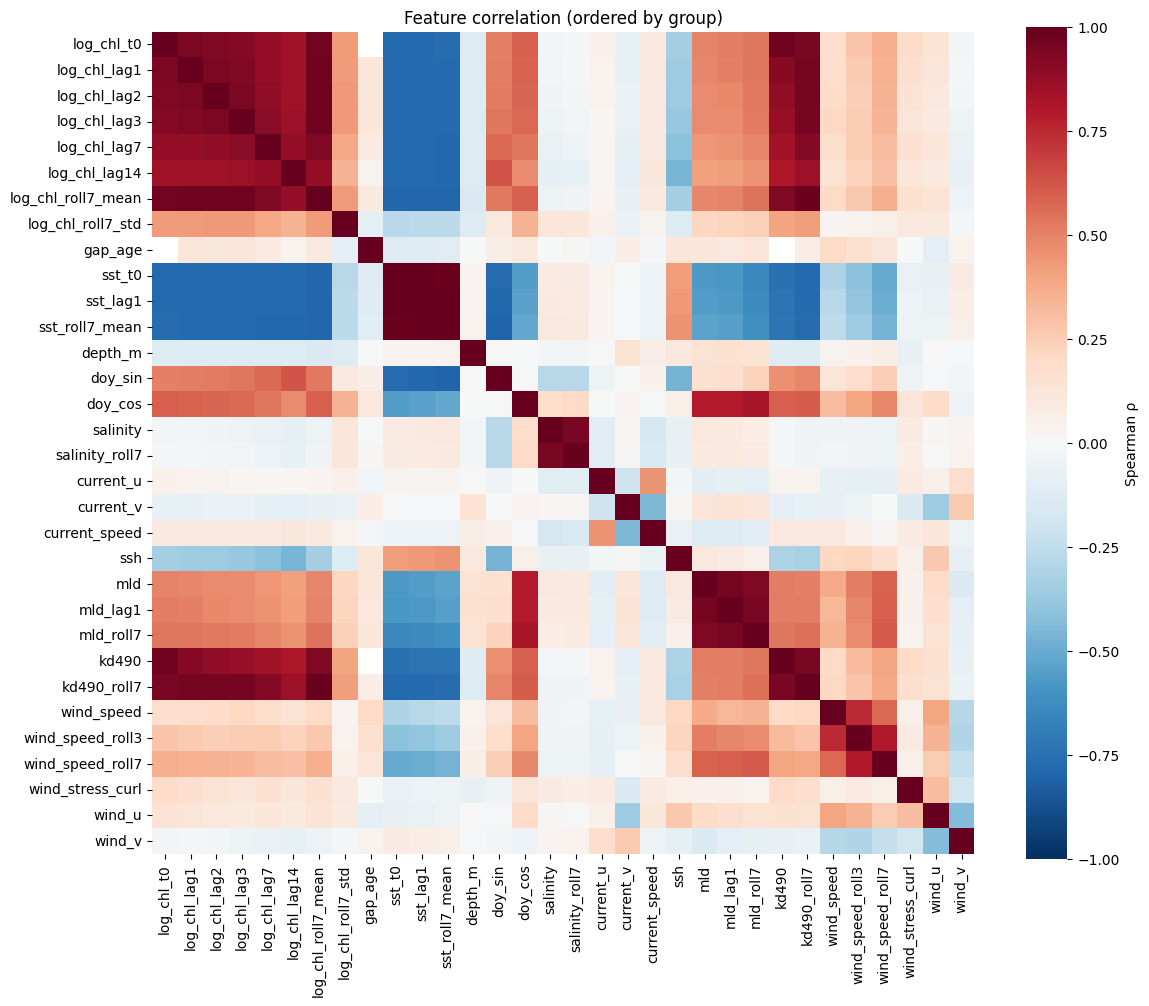


28 pairs with |ρ| ≥ 0.9:
  log_chl_t0             log_chl_lag1           ρ = +0.942
  log_chl_t0             log_chl_lag2           ρ = +0.925
  log_chl_t0             log_chl_lag3           ρ = +0.909
  log_chl_t0             log_chl_roll7_mean     ρ = +0.964
  log_chl_t0             kd490                  ρ = +0.975
  log_chl_t0             kd490_roll7            ρ = +0.951
  log_chl_lag1           log_chl_lag2           ρ = +0.943
  log_chl_lag1           log_chl_lag3           ρ = +0.924
  log_chl_lag1           log_chl_roll7_mean     ρ = +0.970
  log_chl_lag1           kd490                  ρ = +0.907
  log_chl_lag1           kd490_roll7            ρ = +0.957
  log_chl_lag2           log_chl_lag3           ρ = +0.942
  log_chl_lag2           log_chl_roll7_mean     ρ = +0.973
  log_chl_lag2           kd490_roll7            ρ = +0.960
  log_chl_lag3           log_chl_roll7_mean     ρ = +0.975
  log_chl_lag3           kd490_roll7            ρ = +0.960
  log_chl_lag7           log_c

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

# Order columns by group so the heatmap reads as block structure
ordered = [c for g in GROUPS.values() for c in g]
corr = sample[ordered].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, center=0, cmap="RdBu_r", vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True, square=True, ax=ax,
            cbar_kws={"label": "Spearman ρ"})
ax.set_title("Feature correlation (ordered by group)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(FIG_DIR / "08_correlation_heatmap.png", dpi=150)
plt.show()

# Flag highly correlated pairs (off-diagonal)
pairs = []
for i, a in enumerate(ordered):
    for b in ordered[i+1:]:
        rho = corr.loc[a, b]
        if abs(rho) >= 0.9:
            pairs.append((a, b, rho))

if pairs:
    print(f"\n{len(pairs)} pairs with |ρ| ≥ 0.9:")
    for a, b, rho in pairs:
        print(f"  {a:22s} {b:22s} ρ = {rho:+.3f}")
else:
    print("\nNo pair has |ρ| ≥ 0.9 — group reads are still warranted, but pairs are independent.")

## 8b.7 — Train the all-groups candidate models

Apply the same 2021/2022/2023 chronology, horizon-aware label purge, early-stopping selection, pre-test refit, native NaN handling, and dual evaluation scopes as Notebook 6. One candidate model is trained for every horizon using all 32 features.


In [24]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score

SPLIT_PATH = PROC_DIR / "split_manifest.json"
split_protocol = json.loads(SPLIT_PATH.read_text())

TRAIN_END = pd.Timestamp(split_protocol["train_end"])
VAL_END = pd.Timestamp(split_protocol["validation_end"])

train = sample[sample["time"].dt.year == 2021].copy()
val = sample[sample["time"].dt.year == 2022].copy()
test = sample[sample["time"].dt.year == 2023].copy()

reference = pd.concat([train, val], ignore_index=True)

LABEL_EXTRA_DAYS = (
    2 if base_manifest.get("use_3day_target", False) else 0
)

print(
    f"train: {train.time.min().date()} → "
    f"{train.time.max().date()} ({len(train):,})"
)
print(
    f"val  : {val.time.min().date()} → "
    f"{val.time.max().date()} ({len(val):,})"
)
print(
    f"test : {test.time.min().date()} → "
    f"{test.time.max().date()} ({len(test):,})"
)


def score_arrays(y_true, y_pred):
    return {
        "rmse": float(
            np.sqrt(mean_squared_error(y_true, y_pred))
        ),
        "r2": float(r2_score(y_true, y_pred)),
        "n": int(len(y_true)),
    }


COMMON_PARAMS = {
    "max_depth": 6,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "missing": np.nan,
    "eval_metric": "rmse",
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "n_jobs": -1,
    "random_state": 42,
    "verbosity": 0,
}


def fit_one(features, h, refit_final=True):
    target = f"target_h{h}"
    label_offset = h + LABEL_EXTRA_DAYS

    train_deadline = TRAIN_END - pd.Timedelta(
        days=label_offset
    )
    val_deadline = VAL_END - pd.Timedelta(
        days=label_offset
    )

    train_h = train[
        (train["time"] <= train_deadline)
        & train[target].notna()
    ]

    val_h = val[
        (val["time"] <= val_deadline)
        & val[target].notna()
    ]

    tuning_model = xgb.XGBRegressor(
        n_estimators=1200,
        early_stopping_rounds=50,
        **COMMON_PARAMS,
    )

    tuning_model.fit(
        train_h[features],
        train_h[target],
        eval_set=[(val_h[features], val_h[target])],
        verbose=False,
    )

    best_rounds = int(tuning_model.best_iteration) + 1
    val_prediction = tuning_model.predict(val_h[features])
    val_score = score_arrays(val_h[target], val_prediction)

    result = {
        "tuning_model": tuning_model,
        "best_rounds": best_rounds,
        "val_rmse": val_score["rmse"],
        "val_r2": val_score["r2"],
        "val_n": val_score["n"],
        "train_max_label_time": (
            train_h["time"].max()
            + pd.Timedelta(days=label_offset)
        ),
        "validation_max_label_time": (
            val_h["time"].max()
            + pd.Timedelta(days=label_offset)
        ),
    }

    if not refit_final:
        return result

    reference_deadline = VAL_END - pd.Timedelta(
        days=label_offset
    )

    reference_h = reference[
        (reference["time"] <= reference_deadline)
        & reference[target].notna()
    ]

    final_model = xgb.XGBRegressor(
        n_estimators=best_rounds,
        **COMMON_PARAMS,
    )

    final_model.fit(
        reference_h[features],
        reference_h[target],
        verbose=False,
    )

    common_mask = (
        test[target].notna()
        & test["log_chl_t0"].notna()
    )
    all_mask = test[target].notna()

    common_prediction = final_model.predict(
        test.loc[common_mask, features]
    )
    all_prediction = final_model.predict(
        test.loc[all_mask, features]
    )

    common_score = score_arrays(
        test.loc[common_mask, target],
        common_prediction,
    )
    all_score = score_arrays(
        test.loc[all_mask, target],
        all_prediction,
    )

    result.update({
        "model": final_model,
        "test_rmse": common_score["rmse"],
        "test_r2": common_score["r2"],
        "test_n": common_score["n"],
        "test_all_rmse": all_score["rmse"],
        "test_all_r2": all_score["r2"],
        "test_all_n": all_score["n"],
        "refit_max_label_time": (
            reference_h["time"].max()
            + pd.Timedelta(days=label_offset)
        ),
    })

    return result


full_results = {}

for h in HORIZONS:
    result = fit_one(FEATURE_COLS, h)
    full_results[h] = result

    print(
        f"H+{h} rounds={result['best_rounds']:3d}  "
        f"val R²={result['val_r2']:.4f}  "
        f"2023 common-test R²={result['test_r2']:.4f}  "
        f"N={result['test_n']:,}"
    )

train: 2021-01-01 → 2021-12-31 (120,000)
val  : 2022-01-01 → 2022-12-31 (120,000)
test : 2023-01-01 → 2023-12-30 (120,000)
H+1 rounds=209  val R²=0.8823  2023 common-test R²=0.8787  N=50,166
H+2 rounds=218  val R²=0.8558  2023 common-test R²=0.8387  N=47,278
H+3 rounds=197  val R²=0.8394  2023 common-test R²=0.8107  N=45,124
H+4 rounds=178  val R²=0.8179  2023 common-test R²=0.7962  N=44,819
H+5 rounds=139  val R²=0.8009  2023 common-test R²=0.7733  N=44,218
H+6 rounds=194  val R²=0.8048  2023 common-test R²=0.7603  N=44,020
H+7 rounds=120  val R²=0.8050  2023 common-test R²=0.7647  N=44,010


## 8b.8 — Grouped permutation importance at H+3

On the 2022 validation set, shuffle all columns in one group with a shared row permutation, preserving within-group relationships. Repeat five times and record the mean and standard deviation of the RMSE increase. H+3 is the reference horizon for group selection; all seven horizons are still trained and scored.


In [25]:
REF_H = 3
target = f"target_h{REF_H}"

val_deadline = VAL_END - pd.Timedelta(
    days=REF_H + LABEL_EXTRA_DAYS
)

validation_mask = (
    (val["time"] <= val_deadline)
    & val[target].notna()
)

Xva = val.loc[validation_mask, FEATURE_COLS].copy()
yva = val.loc[validation_mask, target].to_numpy()

model = full_results[REF_H]["tuning_model"]

baseline_prediction = model.predict(Xva)
baseline_rmse = float(
    np.sqrt(
        mean_squared_error(
            yva,
            baseline_prediction,
        )
    )
)

rng = np.random.default_rng(0)
N_REPEATS = 5
perm_rows = []

for group, columns in GROUPS.items():
    deltas = []

    for _ in range(N_REPEATS):
        row_order = rng.permutation(len(Xva))
        X_perm = Xva.copy()

        # One shared row permutation preserves correlations between
        # columns belonging to the same group.
        X_perm.loc[:, columns] = (
            Xva.iloc[row_order][columns].to_numpy()
        )

        prediction = model.predict(X_perm)
        shuffled_rmse = float(
            np.sqrt(mean_squared_error(yva, prediction))
        )
        deltas.append(shuffled_rmse - baseline_rmse)

    perm_rows.append({
        "group": group,
        "n_cols": len(columns),
        "delta_rmse_mean": float(np.mean(deltas)),
        "delta_rmse_std": float(np.std(deltas)),
    })

perm = (
    pd.DataFrame(perm_rows)
    .sort_values("delta_rmse_mean", ascending=False)
    .reset_index(drop=True)
)

print(f"Baseline 2022 validation RMSE: {baseline_rmse:.4f}")
print("\nGrouped permutation importance:")
print(perm.to_string(index=False))

Baseline 2022 validation RMSE: 0.1156

Grouped permutation importance:
       group  n_cols  delta_rmse_mean  delta_rmse_std
 chl_history       9         0.129632        0.000420
 static_time       3         0.040604        0.000193
         sst       3         0.018574        0.000154
      optics       2         0.016491        0.000163
        wind       6         0.004141        0.000056
    salinity       2         0.001502        0.000055
currents_ssh       4         0.000830        0.000023
         mld       3         0.000358        0.000053


## 8b.9 — Retrained group ablation at H+3

Drop each group in turn, retrain the H+3 tuning model under the same chronology, and measure the change in validation R². Ablation tests whether other groups can substitute for the removed information; runtime depends on hardware and selected tree counts.


In [26]:
import time as pytime

baseline = full_results[REF_H]
print(f"Baseline (all groups) val R² = {baseline['val_r2']:.4f}")

abl_rows = []
for group in GROUPS:
    drop_cols = GROUPS[group]
    kept = [c for c in FEATURE_COLS if c not in drop_cols]
    t0 = pytime.time()
    r = fit_one(
        kept,
        REF_H,
        refit_final=False,
    )
    delta_r2 = r["val_r2"] - baseline["val_r2"]
    abl_rows.append(dict(group=group,
                         dropped_n=len(drop_cols),
                         val_r2=r["val_r2"],
                         delta_r2=delta_r2,
                         seconds=pytime.time()-t0))
    print(f"  drop {group:14s} → val R² {r['val_r2']:.4f}  ΔR² {delta_r2:+.4f}  ({pytime.time()-t0:.1f}s)")

ablation = pd.DataFrame(abl_rows).sort_values("delta_r2")   # most negative ΔR² = most useful group
print("\nGroups ordered most-essential to least-essential (most negative ΔR² = most needed):")
print(ablation.to_string(index=False))

Baseline (all groups) val R² = 0.8394
  drop chl_history    → val R² 0.8256  ΔR² -0.0138  (2.2s)
  drop sst            → val R² 0.8317  ΔR² -0.0077  (2.9s)
  drop static_time    → val R² 0.8213  ΔR² -0.0182  (2.4s)
  drop salinity       → val R² 0.8344  ΔR² -0.0050  (2.5s)
  drop currents_ssh   → val R² 0.8384  ΔR² -0.0010  (2.7s)
  drop mld            → val R² 0.8384  ΔR² -0.0010  (2.4s)
  drop optics         → val R² 0.8360  ΔR² -0.0034  (4.8s)
  drop wind           → val R² 0.8314  ΔR² -0.0081  (4.4s)

Groups ordered most-essential to least-essential (most negative ΔR² = most needed):
       group  dropped_n   val_r2  delta_r2  seconds
 static_time          3 0.821262 -0.018150 2.364333
 chl_history          9 0.825634 -0.013778 2.192760
        wind          6 0.831362 -0.008050 4.375745
         sst          3 0.831741 -0.007672 2.948946
    salinity          2 0.834406 -0.005006 2.460515
      optics          2 0.836019 -0.003394 4.833795
         mld          3 0.838407 -0.00100

Joint group evidence:
       group  n_cols  delta_rmse_mean  delta_rmse_std  delta_r2  keep
 chl_history       9          0.12963         0.00042  -0.01378  True
 static_time       3          0.04060         0.00019  -0.01815  True
         sst       3          0.01857         0.00015  -0.00767  True
      optics       2          0.01649         0.00016  -0.00339  True
        wind       6          0.00414         0.00006  -0.00805  True
    salinity       2          0.00150         0.00005  -0.00501  True
currents_ssh       4          0.00083         0.00002  -0.00099  True
         mld       3          0.00036         0.00005  -0.00101  True

Retained groups: ['chl_history', 'sst', 'static_time', 'salinity', 'currents_ssh', 'mld', 'optics', 'wind']
Dropped groups : []
Final features : 32


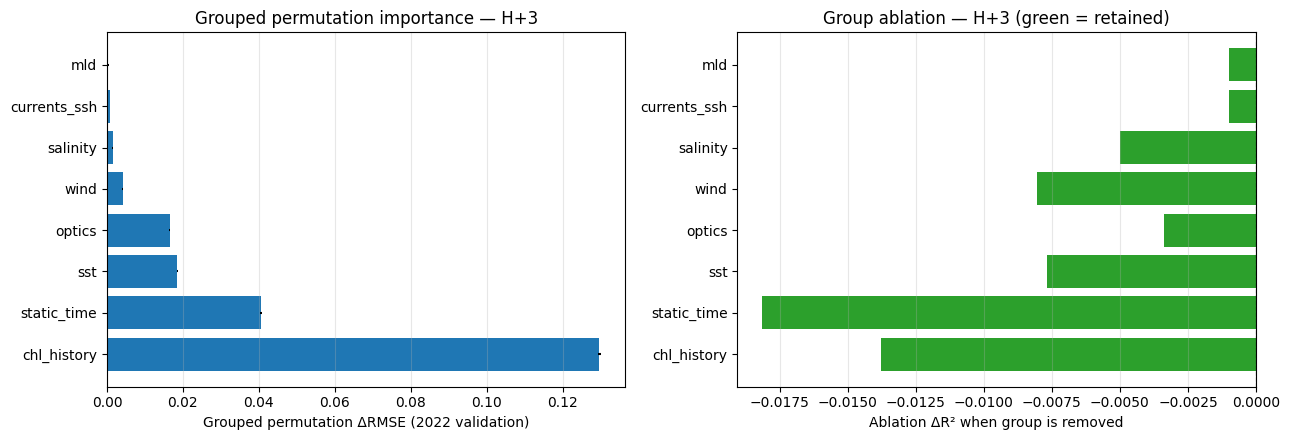

In [29]:
CORE_GROUPS = {
    "chl_history",
    "sst",
    "static_time",
}

joint = (
    perm.merge(ablation, on="group")
    .sort_values(
        "delta_rmse_mean",
        ascending=False,
    )
    .reset_index(drop=True)
)

# For a new group to be retained:
# 1. removing it must reduce validation R²;
# 2. permutation ΔRMSE must exceed twice its repeat SD.
joint["ablation_helps"] = (
    joint["delta_r2"] < 0
)

joint["permutation_measurable"] = (
    joint["delta_rmse_mean"]
    > 2 * joint["delta_rmse_std"]
)

joint["keep"] = (
    joint["group"].isin(CORE_GROUPS)
    | (
        joint["ablation_helps"]
        & joint["permutation_measurable"]
    )
)

keep_by_group = joint.set_index("group")["keep"]

RETAINED_GROUPS = [
    group
    for group in GROUPS
    if bool(keep_by_group.loc[group])
]

DROPPED_GROUPS = [
    group
    for group in GROUPS
    if group not in RETAINED_GROUPS
]

retained_feature_names = {
    column
    for group in RETAINED_GROUPS
    for column in GROUPS[group]
}

# Preserve the exact column order used during model training.
FINAL_FEATURE_COLS = [
    column
    for column in FEATURE_COLS
    if column in retained_feature_names
]

joint.to_csv(
    PROC_DIR / "group_importance.csv",
    index=False,
)

print("Joint group evidence:")
print(
    joint[
        [
            "group",
            "n_cols",
            "delta_rmse_mean",
            "delta_rmse_std",
            "delta_r2",
            "keep",
        ]
    ].round(5).to_string(index=False)
)

print(f"\nRetained groups: {RETAINED_GROUPS}")
print(f"Dropped groups : {DROPPED_GROUPS}")
print(f"Final features : {len(FINAL_FEATURE_COLS)}")

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5),
)

axes[0].barh(
    joint["group"],
    joint["delta_rmse_mean"],
    xerr=joint["delta_rmse_std"],
    color="#1f77b4",
)
axes[0].set_xlabel(
    "Grouped permutation ΔRMSE (2022 validation)"
)
axes[0].set_title(
    "Grouped permutation importance — H+3"
)
axes[0].grid(alpha=0.3, axis="x")

colors = [
    "#2ca02c" if keep else "#bbbbbb"
    for keep in joint["keep"]
]

axes[1].barh(
    joint["group"],
    joint["delta_r2"],
    color=colors,
)
axes[1].axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=0.8,
)
axes[1].set_xlabel(
    "Ablation ΔR² when group is removed"
)
axes[1].set_title(
    "Group ablation — H+3 (green = retained)"
)
axes[1].grid(alpha=0.3, axis="x")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "08_group_importance.png",
    dpi=150,
)

plt.show()

---
## Validation Gate 8b

Core CHL-history, SST, and static/time groups are retained by design. A new group is retained only when removing it lowers validation R² and its grouped permutation RMSE increase exceeds twice the repeat standard deviation. The gate also checks the 360,000-row sample, cloudy issue times, exact chronological splits and label purges, required figures, both evidence tests for every new group, final model/feature-schema agreement, one model per horizon, matched v1/v2 comparison counts, and higher v2 R² at every horizon.

In the validated run all eight groups pass and all 32 features are retained. Artifacts are persisted only after the gate succeeds.


In [30]:
results = {}

results["360,000-row extended sample"] = (
    len(sample) == 360_000
)

results["cloudy issue times retained"] = (
    sample["log_chl_t0"].isna().any()
)

results["train is exactly 2021"] = (
    set(train["time"].dt.year.unique()) == {2021}
)

results["validation is exactly 2022"] = (
    set(val["time"].dt.year.unique()) == {2022}
)

results["test is exactly 2023"] = (
    set(test["time"].dt.year.unique()) == {2023}
)

results["splits are ordered"] = (
    train["time"].max() < val["time"].min()
    and val["time"].max() < test["time"].min()
)

results["training labels do not enter validation"] = all(
    result["train_max_label_time"] <= TRAIN_END
    for result in full_results.values()
)

results["validation labels do not enter test"] = all(
    result["validation_max_label_time"] <= VAL_END
    for result in full_results.values()
)

results["refit labels do not enter test"] = all(
    result["refit_max_label_time"] <= VAL_END
    for result in full_results.values()
)

results["correlation heatmap saved"] = (
    FIG_DIR / "08_correlation_heatmap.png"
).exists()

results["group importance figure saved"] = (
    FIG_DIR / "08_group_importance.png"
).exists()

EXPECTED_NEW_GROUPS = {
    "salinity",
    "currents_ssh",
    "mld",
    "optics",
    "wind",
}

results["every new group retained"] = (
    EXPECTED_NEW_GROUPS
    .issubset(set(RETAINED_GROUPS))
)

new_group_evidence = joint[
    joint["group"].isin(EXPECTED_NEW_GROUPS)
]

results["new groups pass both evidence tests"] = bool(
    (
        new_group_evidence["ablation_helps"]
        & new_group_evidence["permutation_measurable"]
    ).all()
)

# The current corrected models were fitted with every retained feature.
results["saved models match final feature set"] = (
    FINAL_FEATURE_COLS == FEATURE_COLS
)

results["one corrected model per horizon"] = (
    set(full_results) == set(HORIZONS)
    and all(
        "model" in result
        for result in full_results.values()
    )
)

old_scores = (
    pd.read_csv(PROC_DIR / "xgb_scores.csv")
    .set_index("horizon")
    .sort_index()
)

common_rows = []
all_target_rows = []
audit_rows = []

for h in HORIZONS:
    result = full_results[h]

    common_rows.append({
        "method": "xgboost_v2",
        "horizon": h,
        "evaluation_scope": (
            "common_persistence_mask"
        ),
        "best_rounds": result["best_rounds"],
        "rmse": result["test_rmse"],
        "r2": result["test_r2"],
        "n": result["test_n"],
    })

    all_target_rows.append({
        "method": "xgboost_v2",
        "horizon": h,
        "evaluation_scope": (
            "all_observed_targets"
        ),
        "best_rounds": result["best_rounds"],
        "rmse": result["test_all_rmse"],
        "r2": result["test_all_r2"],
        "n": result["test_all_n"],
    })

    audit_rows.append({
        "horizon": h,
        "best_rounds": result["best_rounds"],
        "train_max_label_time": (
            result["train_max_label_time"]
        ),
        "validation_max_label_time": (
            result["validation_max_label_time"]
        ),
        "refit_max_label_time": (
            result["refit_max_label_time"]
        ),
        "common_test_rows": result["test_n"],
        "all_target_test_rows": (
            result["test_all_n"]
        ),
    })

v2_scores = (
    pd.DataFrame(common_rows)
    .sort_values("horizon")
    .reset_index(drop=True)
)

v2_scores_all = (
    pd.DataFrame(all_target_rows)
    .sort_values("horizon")
    .reset_index(drop=True)
)

v2_audit = (
    pd.DataFrame(audit_rows)
    .sort_values("horizon")
    .reset_index(drop=True)
)

v2_by_horizon = v2_scores.set_index("horizon")

results["v1 and v2 use identical comparison counts"] = all(
    int(v2_by_horizon.loc[h, "n"])
    == int(old_scores.loc[h, "n"])
    for h in HORIZONS
)

results["v2 improves R² at every horizon"] = all(
    float(v2_by_horizon.loc[h, "r2"])
    > float(old_scores.loc[h, "r2"])
    for h in HORIZONS
)

for name, passed in results.items():
    print(
        f"{'PASS' if passed else 'FAIL'}  {name}"
    )

print("\nV2 improvement over Notebook 6:")
for h in HORIZONS:
    old_r2 = float(old_scores.loc[h, "r2"])
    new_r2 = float(v2_by_horizon.loc[h, "r2"])

    print(
        f"  H+{h}: "
        f"{old_r2:.4f} → {new_r2:.4f}  "
        f"ΔR²={new_r2 - old_r2:+.4f}"
    )

failed = [
    name
    for name, passed in results.items()
    if not passed
]

if failed:
    raise RuntimeError(
        "Validation Gate 8b failed:\n- "
        + "\n- ".join(failed)
    )

# Persist only after the corrected gate passes.
for h in HORIZONS:
    full_results[h]["model"].save_model(
        str(MODEL_DIR / f"xgb_v2_h{h}.json")
    )

v2_scores.to_csv(
    PROC_DIR / "xgb_v2_scores.csv",
    index=False,
)

v2_scores_all.to_csv(
    PROC_DIR / "xgb_v2_scores_all_targets.csv",
    index=False,
)

v2_audit.to_csv(
    PROC_DIR / "xgb_v2_training_audit.csv",
    index=False,
)

manifest_v2.update({
    "feature_cols": FINAL_FEATURE_COLS,
    "retained_groups": RETAINED_GROUPS,
    "dropped_groups": DROPPED_GROUPS,
    "group_selection_rule": (
        "Retain core groups; retain new groups when "
        "ablation delta R2 is negative and grouped "
        "permutation delta RMSE exceeds twice its "
        "repeat standard deviation."
    ),
    "split_manifest": str(SPLIT_PATH),
    "model_policy": split_protocol["model_policy"],
    "primary_evaluation_scope": (
        "common_persistence_mask"
    ),
})

(PROC_DIR / "feature_manifest_v2.json").write_text(
    json.dumps(manifest_v2, indent=2)
)

model_manifest_v2 = {
    "feature_manifest": str(
        PROC_DIR / "feature_manifest_v2.json"
    ),
    "split_manifest": str(SPLIT_PATH),
    "retained_groups": RETAINED_GROUPS,
    "n_features": len(FINAL_FEATURE_COLS),
    "best_rounds": {
        str(h): int(full_results[h]["best_rounds"])
        for h in HORIZONS
    },
    "score_file": str(
        PROC_DIR / "xgb_v2_scores.csv"
    ),
    "all_target_score_file": str(
        PROC_DIR / "xgb_v2_scores_all_targets.csv"
    ),
}

(PROC_DIR / "xgb_v2_model_manifest.json").write_text(
    json.dumps(model_manifest_v2, indent=2)
)

print("\nGate 8b PASSED.")
print("Saved seven corrected refitted v2 models.")
print("Saved common-mask and all-target v2 scores.")
print("All eight feature groups retained.")
print("Proceed to Notebook 09-Bloom-Detection.")

PASS  360,000-row extended sample
PASS  cloudy issue times retained
PASS  train is exactly 2021
PASS  validation is exactly 2022
PASS  test is exactly 2023
PASS  splits are ordered
PASS  training labels do not enter validation
PASS  validation labels do not enter test
PASS  refit labels do not enter test
PASS  correlation heatmap saved
PASS  group importance figure saved
PASS  every new group retained
PASS  new groups pass both evidence tests
PASS  saved models match final feature set
PASS  one corrected model per horizon
PASS  v1 and v2 use identical comparison counts
PASS  v2 improves R² at every horizon

V2 improvement over Notebook 6:
  H+1: 0.8691 → 0.8787  ΔR²=+0.0096
  H+2: 0.8321 → 0.8387  ΔR²=+0.0066
  H+3: 0.8057 → 0.8107  ΔR²=+0.0050
  H+4: 0.7901 → 0.7962  ΔR²=+0.0061
  H+5: 0.7630 → 0.7733  ΔR²=+0.0103
  H+6: 0.7486 → 0.7603  ΔR²=+0.0117
  H+7: 0.7539 → 0.7647  ΔR²=+0.0107

Gate 8b PASSED.
Saved seven corrected refitted v2 models.
Saved common-mask and all-target v2 scores

---
## Result and next step

The final v2 feature set is supported by two complementary H+3 validation tests while its seven refitted models improve on v1 across the common 2023 comparison masks.

## Next: `09-Bloom-Detection.ipynb`

Convert continuous forecasts into three calibrated event diagnostics: an auxiliary median-plus-5% regime, a rare per-pixel monthly P90 event, and a rare monthly standardized anomaly. Forecast cutoffs are calibrated on 2022 only; cumulative-sum phenology is deferred to full-grid annual inference.
